<a href="https://colab.research.google.com/github/irfan060606/UTS-Machine-Learning-kelompok-14/blob/main/clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UTS Machine Learning — Task 3: Customer Segmentation (Clustering)

**Pemilik pekerjaan: Irfan**  
Notebook ini berisi alur pengerjaan Clustering sesuai instruksi UTS: preprocessing, pemilihan fitur, perbandingan minimal tiga metode, penentuan jumlah cluster, pengujian stabilitas, profil segmen, deteksi anomali, dan pembuatan `cluster.csv`.

## Cara menjalankan di Google Colab
1. Buka [Google Colab](https://colab.research.google.com/) dan unggah notebook ini.
2. Jalankan sel dari atas ke bawah secara berurutan.
3. Saat diminta, unggah **`clustering.csv.gz`** (lebih kecil) atau file hasil ekstrak **`clustering.csv`**.
4. Baca catatan pada setiap bagian. Jangan mengubah hasil hanya demi mendapatkan skor tertentu; catat alasan dan hasil aktualnya.
5. Di bagian akhir, notebook membuat `cluster.csv` (format wajib) dan `profil_cluster.csv` (bahan analisis laporan).

> **Penting:** Notebook ini sudah berisi kode dan penjelasan, tetapi output hasil analisis belum ada sebelum kamu menjalankan semua sel menggunakan dataset. File data tidak disisipkan ke dalam notebook; kamu perlu mengunggah dataset saat menjalankannya di Colab.

## Konteks dataset dari `kamus_data.md`
- Satu baris mewakili satu pelanggan, berupa ringkasan 90 hari terakhir.
- Tidak ada label target untuk Clustering.
- Fitur `porsi_<kategori>` (16 kolom) dan empat fitur `porsi_jam_*` adalah data komposisi: masing-masing kelompok berjumlah kira-kira 1.
- `id_pelanggan` hanya identitas, bukan fitur untuk mengelompokkan.
- Kamus menjelaskan `n01–n10`, tetapi file yang diperiksa berisi `n01–n15`. Notebook mempertahankan fitur anonim secara default untuk diuji, tetapi hasilnya perlu dibandingkan dengan versi tanpa fitur anonim dan dibahas sebagai keterbatasan interpretasi.

## 0. Instalasi dan import library

In [1]:
%pip -q install hdbscan

In [2]:
import io
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
)

import hdbscan

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

print('Pandas:', pd.__version__)
print('Notebook siap. Random state =', RANDOM_STATE)

Pandas: 2.2.3
Notebook siap. Random state = 42


## 1. Memasukkan dataset

Pilih salah satu file yang kamu punya:
- `clustering.csv.gz` — file terkompresi, disarankan karena lebih kecil.
- `clustering.csv` — file CSV hasil ekstrak.

Kode berikut menerima kedua format tersebut.

In [3]:
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise ValueError('Belum ada file yang diunggah. Upload clustering.csv.gz atau clustering.csv.')

valid_names = [name for name in uploaded if name.lower().endswith(('.csv', '.csv.gz'))]
if not valid_names:
    raise ValueError('File harus berekstensi .csv atau .csv.gz.')

DATA_FILENAME = valid_names[0]
print('Membaca:', DATA_FILENAME)
df = pd.read_csv(io.BytesIO(uploaded[DATA_FILENAME]), compression='infer')

print('Ukuran dataset:', df.shape)
display(df.head())

Saving clustering.csv to clustering.csv
Membaca: clustering.csv
Ukuran dataset: (120000, 60)


,id_pelanggan,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,porsi_fashion,porsi_elektronik,porsi_kecantikan,porsi_rumah_tangga,porsi_makanan_minuman,porsi_ibu_bayi,porsi_olahraga,porsi_hobi,porsi_otomotif,porsi_kesehatan,porsi_buku_alat_tulis,porsi_voucher_digital,porsi_gadget_aksesoris,porsi_perabot,porsi_pertanian,porsi_lainnya,porsi_jam_pagi,porsi_jam_siang,porsi_jam_sore,porsi_jam_malam,persen_voucher,persen_flash_sale,persen_paylater,persen_cod,retur_90h,rating_beri_rata2,ulasan_90h,sesi_per_minggu,durasi_sesi_menit,rasio_konversi,lama_member_bulan,umur,kota_tier,perangkat,jumlah_alamat,wishlist,klik_iklan_30h,belanja_30h,frekuensi_30h,n01,n02,n03,n04,n05,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15
0,C864291,8.8000,6,"540,100.0000","90,000.0000",3,0.0052,0.0332,0.0885,0.2438,0.1609,0.1198,0.0133,0.0008,0.0666,0.0600,0.0124,0.0355,0.0025,0.0507,0.0369,0.0701,0.0788,0.3856,0.2537,0.2818,0.4680,0.0190,0.1100,0.4100,1,4.1200,0,9.0700,7.4600,0.0510,16.5000,33,2,ios,1,0,2,"226,600.0000",2,80.8410,6.4240,4.0000,0.3870,6.8200,0.0710,-1.8720,36.1080,3.4070,4.0000,-0.4130,3.4680,0.9430,0.3770,23.3280
1,C115620,14.6000,6,"6,035,900.0000","1,006,000.0000",3,0.1721,0.1303,0.1001,0.1456,0.0474,0.0011,0.0443,0.1306,0.0000,0.0495,0.0107,0.0945,0.0098,0.0389,0.0251,0.0000,0.2587,0.1288,0.3974,0.2152,0.0290,0.1840,0.0130,0.0550,0,4.3400,2,4.2200,10.1200,0.1090,26.9000,42,1,ios,1,5,7,"897,500.0000",2,20.8680,10.9440,6.0000,0.5010,19.1580,0.0060,0.2300,41.0690,6.2180,5.0000,-15.5300,4.8490,0.9980,-2.1100,67.9950
2,C903774,4.1000,15,"4,006,600.0000","267,100.0000",1,0.0636,0.0000,0.0164,0.2187,0.1466,0.2112,0.0433,0.0828,0.0258,0.0690,0.0169,0.0003,0.0264,0.0370,0.0151,0.0269,0.3492,0.3385,0.2212,0.0910,0.2660,0.0550,0.2080,0.1870,1,4.5000,3,3.2500,9.0000,0.3550,10.8000,39,1,ios,1,5,5,"812,500.0000",6,73.8850,4.8040,6.0000,-0.6690,3.4080,0.8880,-0.8480,80.6200,3.5520,6.0000,2.8810,4.2690,0.0020,-0.8120,82.0820
3,C716498,21.9000,2,"659,500.0000","329,800.0000",1,0.1899,0.1197,0.0040,0.0536,0.0261,0.0239,0.0195,0.1593,0.0107,0.0493,0.0001,0.0070,0.2974,0.0102,0.0072,0.0221,0.2225,0.3555,0.1737,0.2483,0.6810,0.6820,0.0990,0.4440,3,4.5100,1,7.3100,10.4800,0.0210,1.5000,30,1,android,2,6,2,"193,700.0000",2,79.5510,19.9520,2.0000,1.2740,3.2310,0.6080,1.0760,86.4650,2.9780,3.0000,2.7900,10.4090,0.1830,0.2850,82.9940
4,C936513,7.0000,8,"4,056,500.0000","507,100.0000",4,0.0045,0.0503,0.0325,0.0326,0.5501,0.0603,0.0172,0.0024,0.0010,0.0015,0.0393,0.1869,0.0154,0.0011,0.0048,0.0000,0.1539,0.3564,0.3492,0.1405,0.6860,0.0730,0.1190,0.2300,0,4.3500,3,8.1700,9.2000,0.0750,29.5000,37,3,ios,1,11,8,"1,876,300.0000",4,23.1420,89.5570,3.0000,1.0540,8.8810,0.8290,-0.6210,47.0960,6.0210,3.0000,-24.9850,7.7960,0.8120,1.2620,60.3640


## 2. Pemeriksaan awal dan kesesuaian kolom

In [4]:
print('Jumlah baris:', len(df))
print('Jumlah kolom:', len(df.columns))
print('\nTipe data:')
display(df.dtypes.value_counts().rename_axis('tipe').to_frame('jumlah kolom'))

required_cols = {'id_pelanggan', 'frekuensi_90h', 'belanja_90h', 'perangkat', 'kota_tier'}
missing_required = required_cols - set(df.columns)
if missing_required:
    raise ValueError(f'Kolom penting tidak ditemukan: {sorted(missing_required)}')

print('Jumlah ID pelanggan unik:', df['id_pelanggan'].nunique())
print('ID pelanggan duplikat:', df['id_pelanggan'].duplicated().sum())
print('Baris duplikat identik:', df.duplicated().sum())

Jumlah baris: 120000
Jumlah kolom: 60

Tipe data:


,jumlah kolom
tipe,
float64,48
int64,10
object,2


Jumlah ID pelanggan unik: 120000
ID pelanggan duplikat: 0
Baris duplikat identik: 0


## 3. Data audit: nilai kosong, nilai tak hingga, komposisi, dan kategori

In [5]:
# Ringkasan nilai kosong
missing_summary = df.isna().sum().sort_values(ascending=False)
missing_summary = missing_summary[missing_summary > 0]
if len(missing_summary):
    display(missing_summary.rename('jumlah_kosong').to_frame())
else:
    print('Tidak ada nilai kosong.')

# Nilai tak hingga hanya dapat diperiksa pada kolom numerik
numeric_raw = df.select_dtypes(include='number')
inf_count = np.isinf(numeric_raw.to_numpy()).sum()
print('Jumlah nilai +inf/-inf pada fitur numerik:', int(inf_count))

# Periksa konteks nilai rata2_keranjang yang kosong
if 'rata2_keranjang' in df.columns:
    miss_basket = df['rata2_keranjang'].isna()
    print('Jumlah rata2_keranjang kosong:', int(miss_basket.sum()))
    inconsistent_basket_missing = []
    for c in ['frekuensi_90h', 'belanja_90h', 'frekuensi_30h', 'belanja_30h']:
        if c in df.columns:
            nonzero_count = int((df.loc[miss_basket, c].fillna(0) != 0).sum())
            print(f'{c}: jumlah nilai bukan nol pada baris dengan keranjang kosong =', nonzero_count)
            if nonzero_count > 0:
                inconsistent_basket_missing.append(c)
    if inconsistent_basket_missing:
        raise ValueError(
            'Ada pelanggan dengan rata2_keranjang kosong tetapi aktivitas belanjanya tidak nol. '
            'Tinjau aturan imputasi sebelum melanjutkan. Kolom: ' + str(inconsistent_basket_missing)
        )
    else:
        print('Audit lolos: nilai rata2_keranjang kosong hanya muncul pada pelanggan tanpa transaksi pada kolom yang diperiksa.')

# Periksa fitur komposisi
TIME_SHARE_COLS = ['porsi_jam_pagi', 'porsi_jam_siang', 'porsi_jam_sore', 'porsi_jam_malam']
CATEGORY_SHARE_COLS = [
    c for c in df.columns
    if c.startswith('porsi_') and c not in TIME_SHARE_COLS
]

for label, cols in [('Porsi kategori', CATEGORY_SHARE_COLS), ('Porsi waktu', TIME_SHARE_COLS)]:
    present = [c for c in cols if c in df.columns]
    if present:
        row_sum = df[present].sum(axis=1)
        print(f'{label}: kolom={len(present)}, rentang jumlah per baris='
              f'{row_sum.min():.5f} sampai {row_sum.max():.5f}')
        print('  Banyak baris yang jumlahnya berbeda dari 1 lebih dari 0.01:',
              int((np.abs(row_sum - 1) > 0.01).sum()))

print('\nKategori perangkat:')
display(df['perangkat'].value_counts(dropna=False).to_frame('jumlah'))
print('Kategori kota_tier:')
display(df['kota_tier'].value_counts(dropna=False).sort_index().to_frame('jumlah'))

,jumlah_kosong
rata2_keranjang,6736


Jumlah nilai +inf/-inf pada fitur numerik: 0
Jumlah rata2_keranjang kosong: 6736
frekuensi_90h: jumlah nilai bukan nol pada baris dengan keranjang kosong = 0
belanja_90h: jumlah nilai bukan nol pada baris dengan keranjang kosong = 0
frekuensi_30h: jumlah nilai bukan nol pada baris dengan keranjang kosong = 0
belanja_30h: jumlah nilai bukan nol pada baris dengan keranjang kosong = 0
Audit lolos: nilai rata2_keranjang kosong hanya muncul pada pelanggan tanpa transaksi pada kolom yang diperiksa.
Porsi kategori: kolom=16, rentang jumlah per baris=0.99960 sampai 1.00050
  Banyak baris yang jumlahnya berbeda dari 1 lebih dari 0.01: 0
Porsi waktu: kolom=4, rentang jumlah per baris=0.99990 sampai 1.00010
  Banyak baris yang jumlahnya berbeda dari 1 lebih dari 0.01: 0

Kategori perangkat:


,jumlah
perangkat,
android,77760
ios,31710
web,10530


Kategori kota_tier:


,jumlah
kota_tier,
1,47961
2,41741
3,30298


### Catatan audit awal

Pada salinan dataset yang diperiksa saat notebook ini disiapkan, terdapat 120.000 baris dan 60 kolom. Sebanyak 6.736 nilai `rata2_keranjang` kosong ditemukan pada pelanggan dengan frekuensi dan total belanja 90 hari sebesar nol. Saat menjalankan notebook, periksa kembali angka tersebut dari output dataset yang kamu unggah.

Untuk kasus tersebut, notebook akan membuat indikator `rata2_keranjang_tidak_tersedia` dan mengisi nilai rata-rata keranjang yang kosong menjadi 0 **hanya sebagai representasi numerik untuk pelanggan tanpa transaksi**. Indikator terpisah menjaga informasi bahwa nilai awalnya memang tidak tersedia. Jika hasil auditmu berbeda, jangan lanjutkan tanpa meninjau aturan imputasi ini.

Nilai porsi kategori dan porsi waktu merupakan komposisi. Notebook menggunakan transformasi *centered log-ratio* (CLR) dengan penggantian nol kecil agar nilai log terdefinisi. Ini adalah keputusan preprocessing yang perlu disebutkan di laporan.

## 4. Exploratory Data Analysis (EDA) ringkas

,count,mean,std,min,25%,50%,75%,max
recency_hari,"120,000.0000",24.5434,49.0098,0.2000,5.4000,10.1000,21.8000,"2,039.8000"
frekuensi_90h,"120,000.0000",9.7054,10.9223,0.0000,3.0000,7.0000,13.0000,204.0000
belanja_90h,"120,000.0000","2,936,216.4267","5,716,273.2068",0.0000,"410,300.0000","1,136,500.0000","3,060,225.0000","261,836,800.0000"
rata2_keranjang,"113,264.0000","280,384.3304","300,796.6191","9,800.0000","108,800.0000","183,900.0000","330,500.0000","6,457,500.0000"
persen_voucher,"120,000.0000",0.5094,0.2832,0.0030,0.2590,0.5080,0.7650,0.9980
persen_flash_sale,"120,000.0000",0.4101,0.2644,0.0020,0.1760,0.3680,0.6290,0.9940
sesi_per_minggu,"120,000.0000",10.0725,31.2044,0.1900,3.3300,5.5100,8.6000,399.9000
rasio_konversi,"120,000.0000",0.1453,0.1738,0.0000,0.0410,0.0940,0.1860,4.2770
umur,"120,000.0000",32.8522,8.6267,17.0000,26.0000,33.0000,39.0000,66.0000
lama_member_bulan,"120,000.0000",20.6138,18.0229,0.3000,9.5000,16.0000,26.1000,376.6000


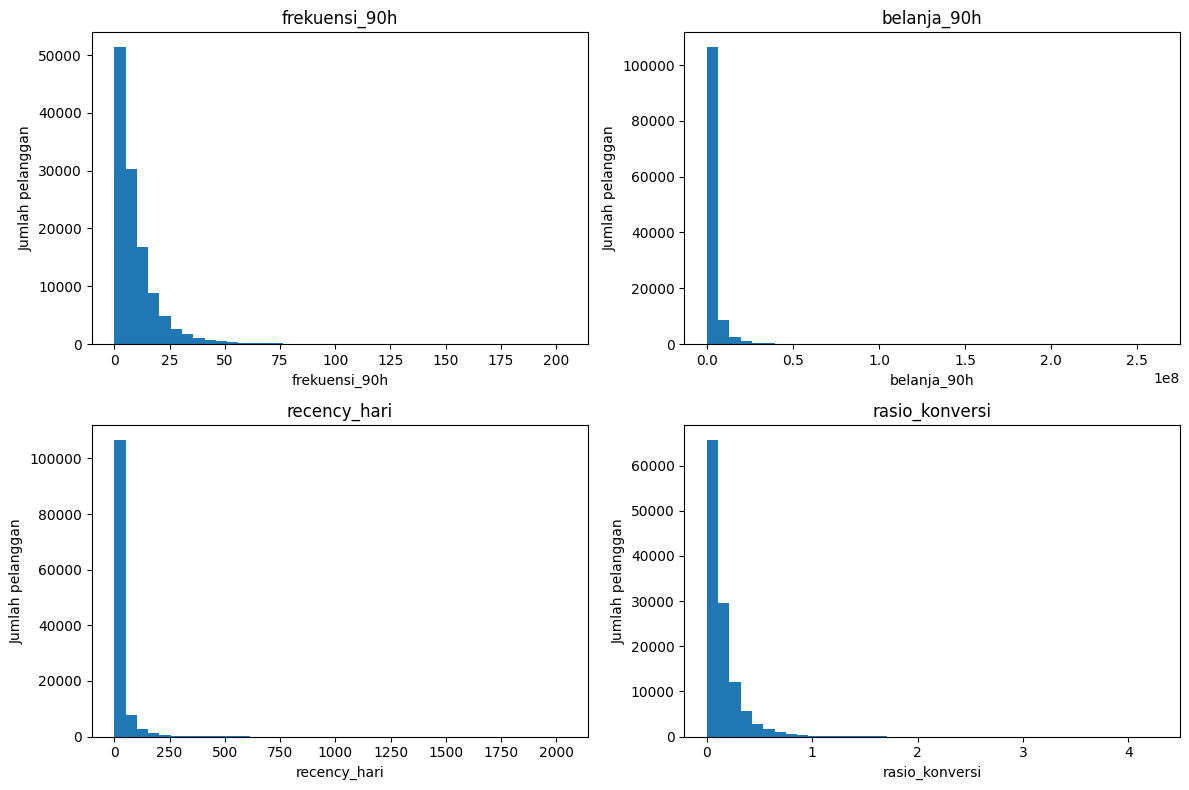

In [6]:
eda_cols = [c for c in [
    'recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang',
    'persen_voucher', 'persen_flash_sale', 'sesi_per_minggu', 'rasio_konversi',
    'umur', 'lama_member_bulan'
] if c in df.columns]

display(df[eda_cols].describe().T)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_cols = ['frekuensi_90h', 'belanja_90h', 'recency_hari', 'rasio_konversi']
for ax, col in zip(axes.ravel(), plot_cols):
    if col in df.columns:
        ax.hist(df[col].dropna(), bins=40)
        ax.set_title(col)
        ax.set_xlabel(col)
        ax.set_ylabel('Jumlah pelanggan')
plt.tight_layout()
plt.show()

## 5. Preprocessing dan pemilihan fitur

Keputusan fitur dalam notebook:
1. `id_pelanggan` dikeluarkan karena hanya identitas, bukan perilaku pelanggan.
2. Kolom `porsi_*` tidak dipakai sebagai angka mentah; setiap kelompok porsi diubah dengan CLR karena data tersebut bersifat komposisional.
3. Kolom aktivitas/nominal yang non-negatif dan cenderung menceng kanan ditransformasi dengan `log1p` sebelum penskalaan.
4. `kota_tier` dan `perangkat` diperlakukan sebagai kategori dan di-*one-hot encode* agar kode kategori tidak dianggap sebagai jarak numerik.
5. Fitur numerik diskalakan dengan `RobustScaler` agar lebih tahan terhadap nilai ekstrem dibanding StandardScaler.
6. `n01–n15` dipertahankan secara default sebagai fitur CRM anonim. Karena kamus menyebut `n01–n10` tetapi file berisi `n01–n15`, jalankan analisis sensitivitas tanpa kolom anonim sebelum menetapkan interpretasi akhir.

Pemilihan akhir fitur tetap harus didukung hasil evaluasi dan pemahaman bisnis, bukan hanya memasukkan semua kolom secara otomatis.

In [7]:
# Pengaturan fitur anonim. Ubah menjadi False untuk analisis sensitivitas tanpa n01-n15.
INCLUDE_ANONYMOUS_FEATURES = False

ANONYMOUS_COLS = [c for c in df.columns if re.fullmatch(r'n\d+', c)]
print('Fitur anonim ditemukan:', ANONYMOUS_COLS)
print('Akan digunakan:', INCLUDE_ANONYMOUS_FEATURES)

# Kelompok komposisi yang tersedia pada file aktual
TIME_SHARE_COLS = [c for c in TIME_SHARE_COLS if c in df.columns]
CATEGORY_SHARE_COLS = [c for c in CATEGORY_SHARE_COLS if c in df.columns]

# CLR: ganti nol dengan epsilon, tutup kembali agar jumlah baris = 1,
# ambil log, lalu kurangi rata-rata log pada baris tersebut.
def clr_transform(frame, columns, epsilon=1e-6):
    values = frame[columns].astype(float).to_numpy()
    values = np.where(np.isfinite(values), values, np.nan)
    if np.isnan(values).any():
        col_medians = np.nanmedian(values, axis=0)
        inds = np.where(np.isnan(values))
        values[inds] = np.take(col_medians, inds[1])
    values = np.clip(values, 0, None)
    values = np.maximum(values, epsilon)
    values = values / values.sum(axis=1, keepdims=True)
    log_values = np.log(values)
    clr_values = log_values - log_values.mean(axis=1, keepdims=True)
    return pd.DataFrame(clr_values, columns=[f'clr_{c}' for c in columns], index=frame.index)

# Bina feature table daripada data asal
features = df.drop(columns=['id_pelanggan']).copy()

# Jika rata2_keranjang kosong, tambahkan indikator sebelum mengisi nilai
if 'rata2_keranjang' in features.columns:
    features['rata2_keranjang_tidak_tersedia'] = features['rata2_keranjang'].isna().astype(int)
    # Audit pada sel sebelumnya perlu memastikan nilai kosong menandai tanpa transaksi.
    features['rata2_keranjang'] = features['rata2_keranjang'].fillna(0)

# Ganti nilai inf dengan NaN agar bisa ditangani imputer
features = features.replace([np.inf, -np.inf], np.nan)

# Buat fitur CLR dan buang proporsi mentah agar tidak dihitung dua kali
composition_cols = CATEGORY_SHARE_COLS + TIME_SHARE_COLS
clr_frames = []
if CATEGORY_SHARE_COLS:
    clr_frames.append(clr_transform(features, CATEGORY_SHARE_COLS))
if TIME_SHARE_COLS:
    clr_frames.append(clr_transform(features, TIME_SHARE_COLS))
features = features.drop(columns=composition_cols, errors='ignore')
if clr_frames:
    features = pd.concat([features] + clr_frames, axis=1)

# Fitur kategorikal
categorical_cols = [c for c in ['kota_tier', 'perangkat'] if c in features.columns]
for c in categorical_cols:
    features[c] = features[c].astype('string')

# Fitur anonim dapat dikeluarkan untuk uji sensitivitas
if not INCLUDE_ANONYMOUS_FEATURES:
    features = features.drop(columns=ANONYMOUS_COLS, errors='ignore')

# Log-transform hanya fitur non-negatif yang sangat mungkin menceng kanan
LOG1P_CANDIDATES = [
    'recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang',
    'item_per_pesanan', 'retur_90h', 'ulasan_90h', 'sesi_per_minggu',
    'durasi_sesi_menit', 'rasio_konversi', 'lama_member_bulan',
    'wishlist', 'klik_iklan_30h', 'belanja_30h', 'frekuensi_30h'
]
log1p_cols = []
for c in LOG1P_CANDIDATES:
    if c in features.columns and pd.to_numeric(features[c], errors='coerce').min() >= 0:
        features[c] = np.log1p(pd.to_numeric(features[c], errors='coerce'))
        log1p_cols.append(c)

numeric_cols = [c for c in features.columns if c not in categorical_cols]

numeric_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])
categorical_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

transformers = [('numeric', numeric_pipe, numeric_cols)]
if categorical_cols:
    transformers.append(('categorical', categorical_pipe, categorical_cols))
preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder='drop',
    verbose_feature_names_out=False
)

X_scaled = preprocessor.fit_transform(features)
X_scaled = np.asarray(X_scaled, dtype=np.float32)
feature_names = preprocessor.get_feature_names_out()

print('Jumlah fitur setelah preprocessing:', X_scaled.shape[1])
print('Jumlah baris:', X_scaled.shape[0])
print('Kolom log1p:', log1p_cols)
print('Contoh nama fitur hasil transformasi:', list(feature_names[:15]))
print('Apakah semua nilai finite?', bool(np.isfinite(X_scaled).all()))

Fitur anonim ditemukan: ['n01', 'n02', 'n03', 'n04', 'n05', 'n06', 'n07', 'n08', 'n09', 'n10', 'n11', 'n12', 'n13', 'n14', 'n15']
Akan digunakan: False
Jumlah fitur setelah preprocessing: 49
Jumlah baris: 120000
Kolom log1p: ['recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang', 'item_per_pesanan', 'retur_90h', 'ulasan_90h', 'sesi_per_minggu', 'durasi_sesi_menit', 'rasio_konversi', 'lama_member_bulan', 'wishlist', 'klik_iklan_30h', 'belanja_30h', 'frekuensi_30h']
Contoh nama fitur hasil transformasi: ['recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang', 'item_per_pesanan', 'persen_voucher', 'persen_flash_sale', 'persen_paylater', 'persen_cod', 'retur_90h', 'rating_beri_rata2', 'ulasan_90h', 'sesi_per_minggu', 'durasi_sesi_menit', 'rasio_konversi']
Apakah semua nilai finite? True


### Penjelasan singkat transformasi komposisi

Misalnya seorang pelanggan membagi belanjanya ke beberapa kategori dengan porsi yang jumlahnya 1. Nilai-nilai ini saling bergantung: jika satu porsi naik, porsi lain harus menyesuaikan. Karena itu, porsi tidak diperlakukan seperti pengukuran biasa. CLR mengubah setiap porsi menjadi log-rasio terhadap rata-rata geometrik porsi pada baris pelanggan yang sama.

### Pemeriksaan fitur anonim

Untuk analisis sensitivitas yang lebih kuat, ubah `INCLUDE_ANONYMOUS_FEATURES` menjadi `False`, lalu pilih **Runtime → Restart session and run all** agar seluruh objek dibuat ulang dari awal. Bandingkan silhouette, Davies–Bouldin, stabilitas ARI, dan profil segmennya dengan hasil yang memakai fitur anonim. Jangan memberi arti bisnis pada `n01–n15` karena kamus data tidak menerangkan semua kolom tersebut.

## 6. Reduksi dimensi untuk perbandingan algoritma

PCA dipakai sebagai representasi ringkas untuk membuat perbandingan model berbasis jarak dan density lebih praktis. Kita memakai 10 komponen utama dan melaporkan proporsi variansi yang dijelaskan. Ini adalah keputusan teknis yang perlu ditinjau; jika variansi yang dijelaskan terlalu rendah, coba 15 atau 20 komponen lalu bandingkan hasilnya.

Ukuran data setelah PCA: (120000, 10)
Total explained variance 10 komponen: 56.962%


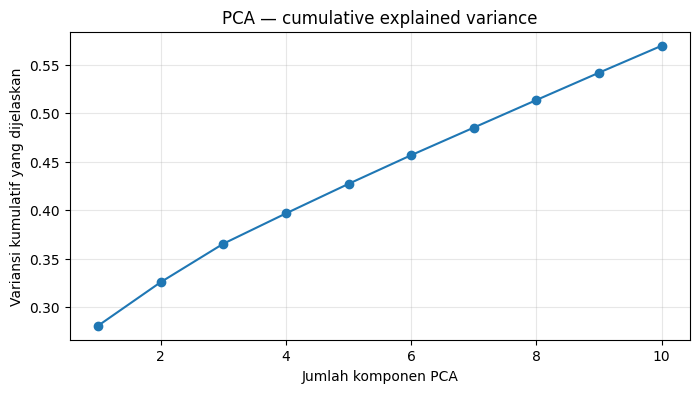

In [8]:
N_PCA_COMPONENTS = min(10, X_scaled.shape[1], X_scaled.shape[0] - 1)
pca = PCA(n_components=N_PCA_COMPONENTS, svd_solver='randomized', random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled).astype(np.float32)
explained = pca.explained_variance_ratio_.sum()
print('Ukuran data setelah PCA:', X_pca.shape)
print(f'Total explained variance {N_PCA_COMPONENTS} komponen: {explained:.3%}')

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1),
         np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel('Jumlah komponen PCA')
plt.ylabel('Variansi kumulatif yang dijelaskan')
plt.title('PCA — cumulative explained variance')
plt.grid(True, alpha=0.3)
plt.show()

## 6A. Uji sensitivitas fitur anonim (dengan vs tanpa n01–n15)

Kamus data menerangkan `n01–n10` sebagai atribut CRM anonim; arti `n11–n15` tidak dirinci, tetapi 15 kolom tersebut muncul pada file aktual. Pengujian ini memakai sampel pelanggan yang sama, jumlah komponen PCA yang sama, rentang k yang sama, dan prosedur stability yang sama agar kedua kondisi dapat dibandingkan secara adil.

Pada kondisi **dengan fitur anonim**, fitur `n01–n15` ditransformasi dengan *signed log* (`sign(x) × log(1 + abs(x))`) sebelum RobustScaler. Ini menjaga nilai negatif tetap dapat diproses dan mengurangi dominasi nilai ekstrem pada fitur yang sangat menceng. Hasil uji mentah tanpa transformasi menunjukkan cluster sangat timpang karena beberapa nilai anonim ekstrem; karena itu hasil utama perbandingan menggunakan transformasi ini.

Kriteria pembacaan: Silhouette lebih tinggi lebih baik, Davies–Bouldin lebih rendah lebih baik, dan ARI stability mendekati 1 lebih konsisten. Metrik internal tidak dapat menggantikan hidden-reference ARI dari dosen, karena label referensi tidak tersedia bagi mahasiswa.


**Hasil verifikasi pada file `clustering.csv` (120.000 pelanggan):** kedua kondisi memilih `k=2`. Tanpa fitur anonim memperoleh Silhouette **0,6617**, Davies–Bouldin **0,4493**, dan variansi 10 komponen PCA **56,96%**. Dengan `n01–n15` (signed log), nilainya **0,6615**, **0,4548**, dan **46,77%**. Setelah `n_init=10`, stability 10 pengulangan pada kedua kondisi menghasilkan rata-rata ARI **1,0000** (SD **0,0000**). Kedua hasil label akhir memiliki ARI **0,9659** dan kesamaan label angka **99,58%**. Dengan demikian, untuk model utama notebook ini dipilih **tanpa fitur anonim**: kualitas pemisahan sedikit lebih baik, dimensi lebih mudah dijelaskan, dan stability setara. Ini keputusan berdasarkan metrik internal; belum membuktikan bahwa hidden-reference ARI dosen pasti lebih tinggi.


In [9]:
# Bandingkan dua kondisi fitur pada pelanggan/sampel yang sama.
# Kondisi tanpa anonim memakai X_scaled dan PCA dari preprocessing utama di atas.
# Kondisi dengan anonim membangun ulang matriks dengan preprocessing identik,
# lalu menambahkan n01-n15 setelah transformasi signed-log.

def build_scaled_with_anonymous_for_sensitivity():
    f_cmp = df.drop(columns=['id_pelanggan']).copy()
    if 'rata2_keranjang' in f_cmp.columns:
        f_cmp['rata2_keranjang_tidak_tersedia'] = f_cmp['rata2_keranjang'].isna().astype(int)
        f_cmp['rata2_keranjang'] = f_cmp['rata2_keranjang'].fillna(0)
    f_cmp = f_cmp.replace([np.inf, -np.inf], np.nan)

    clr_parts = []
    if CATEGORY_SHARE_COLS:
        clr_parts.append(clr_transform(f_cmp, CATEGORY_SHARE_COLS))
    if TIME_SHARE_COLS:
        clr_parts.append(clr_transform(f_cmp, TIME_SHARE_COLS))
    f_cmp = f_cmp.drop(columns=CATEGORY_SHARE_COLS + TIME_SHARE_COLS, errors='ignore')
    if clr_parts:
        f_cmp = pd.concat([f_cmp] + clr_parts, axis=1)

    categorical_cmp = [c for c in ['kota_tier', 'perangkat'] if c in f_cmp.columns]
    for c in categorical_cmp:
        f_cmp[c] = f_cmp[c].astype('string')

    # Signed log untuk seluruh kolom anonim; aman untuk nilai positif maupun negatif.
    for c in ANONYMOUS_COLS:
        x = pd.to_numeric(f_cmp[c], errors='coerce')
        f_cmp[c] = np.sign(x) * np.log1p(np.abs(x))

    log_candidates_cmp = [
        'recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang',
        'item_per_pesanan', 'retur_90h', 'ulasan_90h', 'sesi_per_minggu',
        'durasi_sesi_menit', 'rasio_konversi', 'lama_member_bulan',
        'wishlist', 'klik_iklan_30h', 'belanja_30h', 'frekuensi_30h'
    ]
    for c in log_candidates_cmp:
        if c in f_cmp.columns and pd.to_numeric(f_cmp[c], errors='coerce').min() >= 0:
            f_cmp[c] = np.log1p(pd.to_numeric(f_cmp[c], errors='coerce'))

    numeric_cmp = [c for c in f_cmp.columns if c not in categorical_cmp]
    numeric_pipe_cmp = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ])
    categorical_pipe_cmp = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    transformers_cmp = [('numeric', numeric_pipe_cmp, numeric_cmp)]
    if categorical_cmp:
        transformers_cmp.append(('categorical', categorical_pipe_cmp, categorical_cmp))
    preprocessor_cmp = ColumnTransformer(
        transformers=transformers_cmp, remainder='drop', verbose_feature_names_out=False
    )
    X_cmp = np.asarray(preprocessor_cmp.fit_transform(f_cmp), dtype=np.float32)
    return X_cmp, preprocessor_cmp


def evaluate_feature_condition(X_repr, explained_variance, condition_name):
    # K dan metrik dihitung dari indeks evaluasi yang identik pada kedua kondisi.
    eval_n_cmp = min(20000, len(X_repr))
    rng_cmp = np.random.default_rng(RANDOM_STATE)
    eval_idx_cmp = rng_cmp.choice(len(X_repr), size=eval_n_cmp, replace=False)
    X_eval_cmp = X_repr[eval_idx_cmp]

    rows_cmp = []
    for k_cmp in range(2, 9):
        model_cmp = KMeans(
            n_clusters=k_cmp, random_state=RANDOM_STATE, n_init=10, max_iter=300
        )
        labels_cmp = model_cmp.fit_predict(X_eval_cmp)
        sil_cmp = silhouette_score(
            X_eval_cmp, labels_cmp,
            sample_size=min(3000, len(X_eval_cmp)), random_state=RANDOM_STATE
        )
        db_cmp = davies_bouldin_score(X_eval_cmp, labels_cmp)
        rows_cmp.append({
            'k': k_cmp, 'silhouette': float(sil_cmp),
            'davies_bouldin': float(db_cmp)
        })
    scores_cmp = pd.DataFrame(rows_cmp)
    scores_cmp['rank_silhouette'] = scores_cmp['silhouette'].rank(ascending=False)
    scores_cmp['rank_davies_bouldin'] = scores_cmp['davies_bouldin'].rank(ascending=True)
    scores_cmp['rank_total'] = scores_cmp['rank_silhouette'] + scores_cmp['rank_davies_bouldin']
    scores_cmp = scores_cmp.sort_values(['rank_total', 'k'])
    k_cmp_selected = int(scores_cmp.iloc[0]['k'])

    # Stability: 10 pengulangan, 70% subsampling, holdout sama dalam tiap pasangan model.
    stability_cmp = []
    holdout_cmp_size = min(2000, max(500, len(X_eval_cmp) // 10))
    for rep_cmp in range(10):
        rng_rep = np.random.default_rng(RANDOM_STATE + 100 + rep_cmp)
        all_cmp_idx = np.arange(len(X_eval_cmp))
        rng_rep.shuffle(all_cmp_idx)
        hold_cmp_idx = all_cmp_idx[:holdout_cmp_size]
        pool_cmp_idx = all_cmp_idx[holdout_cmp_size:]
        train_cmp_size = max(k_cmp_selected * 20, int(0.70 * len(pool_cmp_idx)))
        train_cmp_size = min(train_cmp_size, len(pool_cmp_idx))
        train_cmp_a = rng_rep.choice(pool_cmp_idx, size=train_cmp_size, replace=False)
        train_cmp_b = rng_rep.choice(pool_cmp_idx, size=train_cmp_size, replace=False)

        km_cmp_a = MiniBatchKMeans(
            n_clusters=k_cmp_selected, random_state=RANDOM_STATE + rep_cmp,
            n_init=10, batch_size=1024, max_iter=150
        )
        km_cmp_b = MiniBatchKMeans(
            n_clusters=k_cmp_selected, random_state=RANDOM_STATE + 50 + rep_cmp,
            n_init=10, batch_size=1024, max_iter=150
        )
        km_cmp_a.fit(X_eval_cmp[train_cmp_a])
        km_cmp_b.fit(X_eval_cmp[train_cmp_b])
        ari_cmp = adjusted_rand_score(
            km_cmp_a.predict(X_eval_cmp[hold_cmp_idx]),
            km_cmp_b.predict(X_eval_cmp[hold_cmp_idx])
        )
        stability_cmp.append(float(ari_cmp))

    k2 = scores_cmp.loc[scores_cmp['k'] == k_cmp_selected].iloc[0]
    result_cmp = {
        'k_terpilih': k_cmp_selected,
        'silhouette': float(k2['silhouette']),
        'davies_bouldin': float(k2['davies_bouldin']),
        'pca_variansi_10_komponen': float(explained_variance),
        'rata2_ARI_10_pengulangan': float(np.mean(stability_cmp)),
        'sd_ARI': float(np.std(stability_cmp, ddof=1)),
        'ARI_per_pengulangan': stability_cmp,
        'holdout_size': int(holdout_cmp_size),
        'tabel_k': scores_cmp
    }
    return result_cmp

# Matriks tanpa anonim: hasil preprocessing utama (INCLUDE_ANONYMOUS_FEATURES=False).
feature_count_without = X_scaled.shape[1]
result_without = evaluate_feature_condition(
    X_pca, pca.explained_variance_ratio_.sum(), 'tanpa_anonymous'
)

# Matriks dengan anonim: transformasi yang sama + signed-log pada n01-n15.
X_scaled_with_anonymous, preprocessor_with_anonymous = build_scaled_with_anonymous_for_sensitivity()
feature_count_with = X_scaled_with_anonymous.shape[1]
pca_with_anonymous = PCA(
    n_components=min(N_PCA_COMPONENTS, X_scaled_with_anonymous.shape[1], X_scaled_with_anonymous.shape[0] - 1),
    svd_solver='randomized', random_state=RANDOM_STATE
)
X_pca_with_anonymous = pca_with_anonymous.fit_transform(X_scaled_with_anonymous).astype(np.float32)
result_with = evaluate_feature_condition(
    X_pca_with_anonymous, pca_with_anonymous.explained_variance_ratio_.sum(), 'dengan_anonymous'
)

feature_sensitivity_summary = pd.DataFrame([
    {
        'kondisi_fitur': 'Tanpa n01-n15',
        'jumlah_fitur_setelah_preprocessing': feature_count_without,
        'jumlah_komponen_PCA': N_PCA_COMPONENTS,
        'variansi_PCA': result_without['pca_variansi_10_komponen'],
        'k_terpilih': result_without['k_terpilih'],
        'silhouette': result_without['silhouette'],
        'davies_bouldin': result_without['davies_bouldin'],
        'rata2_ARI_10_pengulangan': result_without['rata2_ARI_10_pengulangan'],
        'sd_ARI': result_without['sd_ARI']
    },
    {
        'kondisi_fitur': 'Dengan n01-n15 (signed log)',
        'jumlah_fitur_setelah_preprocessing': feature_count_with,
        'jumlah_komponen_PCA': N_PCA_COMPONENTS,
        'variansi_PCA': result_with['pca_variansi_10_komponen'],
        'k_terpilih': result_with['k_terpilih'],
        'silhouette': result_with['silhouette'],
        'davies_bouldin': result_with['davies_bouldin'],
        'rata2_ARI_10_pengulangan': result_with['rata2_ARI_10_pengulangan'],
        'sd_ARI': result_with['sd_ARI']
    }
])
display(feature_sensitivity_summary.round(4))

# Bandingkan label akhir dari kedua kondisi dengan aturan K-Means dan anomali yang sama.
def fit_labels_for_sensitivity(X_repr, k_final):
    model_final = MiniBatchKMeans(
        n_clusters=k_final, random_state=RANDOM_STATE,
        n_init=10, batch_size=4096, max_iter=300
    )
    raw_final = model_final.fit_predict(X_repr)
    distance_final = np.linalg.norm(X_repr - model_final.cluster_centers_[raw_final], axis=1)
    labels_final = raw_final.copy()
    for cid_final in np.unique(raw_final):
        mask_final = raw_final == cid_final
        threshold_final = np.quantile(distance_final[mask_final], 0.99)
        labels_final[mask_final & (distance_final > threshold_final)] = -1
    return labels_final

labels_without_anonymous = fit_labels_for_sensitivity(X_pca, result_without['k_terpilih'])
labels_with_anonymous = fit_labels_for_sensitivity(
    X_pca_with_anonymous, result_with['k_terpilih']
)
ari_between_feature_sets = adjusted_rand_score(labels_without_anonymous, labels_with_anonymous)
exact_agreement = float(np.mean(labels_without_anonymous == labels_with_anonymous))
print(f'ARI antara label final dengan vs tanpa fitur anonim: {ari_between_feature_sets:.4f}')
print(f'Persentase pelanggan dengan label angka yang sama: {exact_agreement:.2%}')

# Simpan bukti perbandingan. Model utama tetap memakai fitur tanpa anonim.
feature_sensitivity_summary.to_csv('feature_sensitivity_summary.csv', index=False)
stability_sensitivity = pd.DataFrame([
    {'kondisi_fitur': 'Tanpa n01-n15', 'pengulangan': i + 1, 'ARI': ari,
     'proporsi_data_latih_per_model': 0.70, 'jumlah_pelanggan_holdout': result_without['holdout_size'], 'n_init': 10}
    for i, ari in enumerate(result_without['ARI_per_pengulangan'])
] + [
    {'kondisi_fitur': 'Dengan n01-n15 (signed log)', 'pengulangan': i + 1, 'ARI': ari,
     'proporsi_data_latih_per_model': 0.70, 'jumlah_pelanggan_holdout': result_with['holdout_size'], 'n_init': 10}
    for i, ari in enumerate(result_with['ARI_per_pengulangan'])
])
stability_sensitivity.to_csv('stability_sensitivity.csv', index=False)
print('Rekomendasi pada dataset ini: TANPA fitur anonim; Silhouette sedikit lebih tinggi,')
print('Davies-Bouldin lebih rendah, PCA mempertahankan variansi lebih besar, dan stabilitas seri.')
print('Catatan: hidden-reference ARI dosen tidak dapat dihitung karena label referensi tidak tersedia.')

# Lepaskan matriks kondisi anonim agar pemakaian RAM untuk tahap selanjutnya tetap ringan.
del X_scaled_with_anonymous, X_pca_with_anonymous, preprocessor_with_anonymous, pca_with_anonymous


,kondisi_fitur,jumlah_fitur_setelah_preprocessing,jumlah_komponen_PCA,variansi_PCA,k_terpilih,silhouette,davies_bouldin,rata2_ARI_10_pengulangan,sd_ARI
0,Tanpa n01-n15,49,10,0.5696,2,0.6617,0.4493,1.0000,0.0000
1,Dengan n01-n15 (signed log),64,10,0.4677,2,0.6615,0.4548,1.0000,0.0000


ARI antara label final dengan vs tanpa fitur anonim: 0.9659
Persentase pelanggan dengan label angka yang sama: 99.58%
Rekomendasi pada dataset ini: TANPA fitur anonim; Silhouette sedikit lebih tinggi,
Davies-Bouldin lebih rendah, PCA mempertahankan variansi lebih besar, dan stabilitas seri.
Catatan: hidden-reference ARI dosen tidak dapat dihitung karena label referensi tidak tersedia.


## 7. Membuat sampel evaluasi dan menentukan jumlah cluster

Karena dataset berisi 120 ribu pelanggan, proses pencarian jumlah cluster memakai sampel acak yang representatif agar waktu komputasi lebih masuk akal. Model akhir tetap dilatih pada seluruh data (kecuali jika kamu memilih HDBSCAN dan RAM/runtime tidak mencukupi).

Untuk K-Means, jumlah cluster dinilai dengan **dua kriteria**:
- Silhouette: semakin tinggi semakin baik.
- Davies–Bouldin: semakin rendah semakin baik.

Pemilihan `k` menggunakan peringkat gabungan kedua kriteria, bukan satu skor saja.

In [10]:
EVAL_SAMPLE_SIZE = min(20000, len(X_pca))
rng = np.random.default_rng(RANDOM_STATE)
eval_idx = rng.choice(len(X_pca), size=EVAL_SAMPLE_SIZE, replace=False)
X_eval = X_pca[eval_idx]

K_VALUES = range(2, 9)
k_rows = []
for k in K_VALUES:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10, max_iter=300)
    labels = model.fit_predict(X_eval)
    sil = silhouette_score(X_eval, labels, sample_size=min(3000, len(X_eval)), random_state=RANDOM_STATE)
    db = davies_bouldin_score(X_eval, labels)
    k_rows.append({'k': k, 'silhouette': sil, 'davies_bouldin': db, 'inertia': model.inertia_})

k_scores = pd.DataFrame(k_rows)
k_scores['rank_silhouette'] = k_scores['silhouette'].rank(ascending=False)
k_scores['rank_davies_bouldin'] = k_scores['davies_bouldin'].rank(ascending=True)
k_scores['rank_total'] = k_scores['rank_silhouette'] + k_scores['rank_davies_bouldin']
k_scores = k_scores.sort_values(['rank_total', 'k'])
display(k_scores)

k_selected = int(k_scores.iloc[0]['k'])
print('Jumlah cluster K-Means terpilih berdasarkan peringkat dua kriteria:', k_selected)

,k,silhouette,davies_bouldin,inertia,rank_silhouette,rank_davies_bouldin,rank_total
0,2,0.6617,0.4493,"280,408.3438",1.0000,1.0000,2.0000
1,3,0.1796,1.7002,"243,417.7812",2.0000,2.0000,4.0000
5,7,0.1508,1.7463,"196,937.6562",3.0000,3.0000,6.0000
4,6,0.1471,1.8172,"206,211.4531",4.0000,5.0000,9.0000
6,8,0.1470,1.7646,"188,956.4844",5.0000,4.0000,9.0000
3,5,0.1450,1.8533,"215,546.6406",6.0000,6.0000,12.0000
2,4,0.1410,1.8821,"226,011.1875",7.0000,7.0000,14.0000


Jumlah cluster K-Means terpilih berdasarkan peringkat dua kriteria: 2


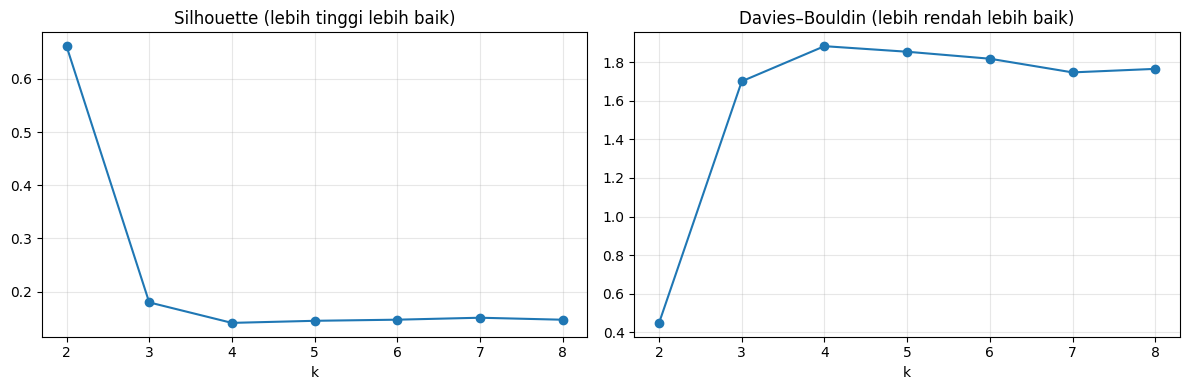

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_scores = k_scores.sort_values('k')
axes[0].plot(plot_scores['k'], plot_scores['silhouette'], marker='o')
axes[0].set_title('Silhouette (lebih tinggi lebih baik)')
axes[0].set_xlabel('k')
axes[1].plot(plot_scores['k'], plot_scores['davies_bouldin'], marker='o')
axes[1].set_title('Davies–Bouldin (lebih rendah lebih baik)')
axes[1].set_xlabel('k')
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Perbandingan tiga metode: K-Means, Gaussian Mixture, dan HDBSCAN

Tiga metode berikut memiliki pendekatan berbeda:
- **K-Means:** membagi pelanggan ke sejumlah cluster berdasarkan jarak ke pusat cluster.
- **Gaussian Mixture Model (GMM):** memodelkan data sebagai campuran beberapa distribusi Gaussian dan memberi probabilitas keanggotaan.
- **HDBSCAN:** mengelompokkan berdasarkan kepadatan dan dapat memberi label `-1` untuk noise/anomali.

GMM memilih jumlah komponen menggunakan BIC pada sampel. HDBSCAN dijalankan pada subset untuk perbandingan metode agar runtime lebih terkendali. Catat ukuran sampel dan parameternya saat menulis laporan.

In [12]:
# GMM: pencarian jumlah komponen menggunakan BIC yang lebih rendah lebih baik
GMM_COMPONENTS = range(2, 9)
gmm_rows = []
gmm_models_sample = {}
for n_comp in GMM_COMPONENTS:
    gm = GaussianMixture(
        n_components=n_comp,
        covariance_type='diag',
        reg_covar=1e-5,
        n_init=1,
        max_iter=150,
        random_state=RANDOM_STATE
    )
    gm.fit(X_eval)
    bic = gm.bic(X_eval)
    gmm_rows.append({'components': n_comp, 'bic': bic, 'aic': gm.aic(X_eval)})
    gmm_models_sample[n_comp] = gm

gmm_scores = pd.DataFrame(gmm_rows).sort_values('bic')
display(gmm_scores)
gmm_selected = int(gmm_scores.iloc[0]['components'])
print('Jumlah komponen GMM terpilih berdasarkan BIC:', gmm_selected)

,components,bic,aic
6,8,"607,419.0279","606,099.1455"
5,7,"608,090.6621","606,936.7529"
4,6,"610,565.2924","609,577.3565"
3,5,"613,389.1323","612,567.1696"
2,4,"616,507.5820","615,851.5925"
1,3,"628,062.5305","627,572.5143"
0,2,"636,663.8244","636,339.7815"


Jumlah komponen GMM terpilih berdasarkan BIC: 8


In [13]:
# HDBSCAN pada subset sampel. HDBSCAN tidak meminta jumlah cluster di awal.
HDBSCAN_SAMPLE_SIZE = min(15000, len(X_eval))
hdb_idx = rng.choice(len(X_eval), size=HDBSCAN_SAMPLE_SIZE, replace=False)
X_hdb = X_eval[hdb_idx]

hdb_model_sample = hdbscan.HDBSCAN(
    min_cluster_size=max(50, int(0.005 * len(X_hdb))),
    min_samples=10,
    metric='euclidean',
    cluster_selection_method='eom',
    core_dist_n_jobs=-1,
    approx_min_span_tree=True
)
hdb_labels_sample = hdb_model_sample.fit_predict(X_hdb)
non_noise = hdb_labels_sample != -1
n_hdb_clusters = len(set(hdb_labels_sample) - {-1})
noise_pct = 100 * np.mean(~non_noise)

hdb_sil = np.nan
hdb_db = np.nan
if n_hdb_clusters >= 2 and non_noise.sum() > 10:
    X_hdb_clean = X_hdb[non_noise]
    labels_hdb_clean = hdb_labels_sample[non_noise]
    hdb_sil = silhouette_score(
        X_hdb_clean, labels_hdb_clean,
        sample_size=min(3000, len(X_hdb_clean)), random_state=RANDOM_STATE
    )
    hdb_db = davies_bouldin_score(X_hdb_clean, labels_hdb_clean)

hdb_summary = pd.DataFrame([{
    'method': 'HDBSCAN',
    'jumlah_cluster_tidak_termasuk_noise': n_hdb_clusters,
    'persen_noise': noise_pct,
    'silhouette_tanpa_noise': hdb_sil,
    'davies_bouldin_tanpa_noise': hdb_db
}])
display(hdb_summary)

,method,jumlah_cluster_tidak_termasuk_noise,persen_noise,silhouette_tanpa_noise,davies_bouldin_tanpa_noise
0,HDBSCAN,2,0.0000,0.6605,0.4490


In [14]:
# Ringkasan komparasi metode pada sampel evaluasi
k_best_row = k_scores.sort_values('rank_total').iloc[0]
gmm_best_model = gmm_models_sample[gmm_selected]
gmm_sample_labels = gmm_best_model.predict(X_eval)
gmm_sample_sil = silhouette_score(
    X_eval, gmm_sample_labels,
    sample_size=min(3000, len(X_eval)), random_state=RANDOM_STATE
)
gmm_sample_db = davies_bouldin_score(X_eval, gmm_sample_labels)

comparison = pd.DataFrame([
    {
        'metode': 'K-Means',
        'jumlah_cluster': k_selected,
        'silhouette': float(k_best_row['silhouette']),
        'davies_bouldin': float(k_best_row['davies_bouldin']),
        'catatan': 'Dievaluasi pada sampel; dua kriteria dipakai untuk memilih k.'
    },
    {
        'metode': 'Gaussian Mixture',
        'jumlah_cluster': gmm_selected,
        'silhouette': gmm_sample_sil,
        'davies_bouldin': gmm_sample_db,
        'catatan': 'Jumlah komponen dipilih dengan BIC pada sampel.'
    },
    {
        'metode': 'HDBSCAN',
        'jumlah_cluster': n_hdb_clusters,
        'silhouette': hdb_sil,
        'davies_bouldin': hdb_db,
        'catatan': f'Dijalankan pada subset {HDBSCAN_SAMPLE_SIZE:,} baris; noise {noise_pct:.2f}%.'
    }
])
display(comparison)

,metode,jumlah_cluster,silhouette,davies_bouldin,catatan
0,K-Means,2,0.6617,0.4493,Dievaluasi pada sampel; dua kriteria dipakai u...
1,Gaussian Mixture,8,0.0565,3.6378,Jumlah komponen dipilih dengan BIC pada sampel.
2,HDBSCAN,2,0.6605,0.4490,"Dijalankan pada subset 15,000 baris; noise 0.00%."


### Cara membaca perbandingan

Jangan otomatis memilih model hanya karena satu angka paling tinggi. Pertimbangkan:
- Silhouette lebih tinggi dan Davies–Bouldin lebih rendah biasanya mengindikasikan cluster lebih terpisah.
- BIC digunakan untuk membandingkan jumlah komponen GMM; nilainya tidak langsung sebanding dengan Silhouette.
- HDBSCAN mungkin menghasilkan noise (`-1`) dan jumlah cluster yang berbeda. Nilai metrik HDBSCAN di atas dihitung tanpa noise, sehingga perlu dibaca bersama persentase noise.
- Profil pelanggan harus masuk akal dan berguna bagi strategi pemasaran.

Secara default notebook melatih K-Means untuk seluruh pelanggan. Ini dapat diubah setelah kelompok meninjau hasil komparasi dan kapasitas runtime.

## 9. Uji stabilitas cluster dengan subsampling dan ARI

Uji ini mengulang subsampling sebanyak 10 kali. Pada setiap pengulangan, dua model K-Means dilatih pada dua sampel acak yang masing-masing berisi 70% dari pool pelatihan, lalu prediksinya dibandingkan pada holdout yang sama. Penggunaan 70% mengurangi tumpang tindih sampel dibanding 80%; `n_init=10` membantu mengurangi pengaruh inisialisasi centroid yang kurang baik. ARI mendekati 1 berarti pengelompokan dua model konsisten pada pelanggan holdout.


In [15]:
STABILITY_REPEATS = 10
STABILITY_HOLDOUT_SIZE = min(2000, max(500, len(X_eval) // 10))
STABILITY_TRAIN_FRACTION = 0.70
STABILITY_N_INIT = 10
stability_rows = []

for repeat in range(STABILITY_REPEATS):
    rng_stab = np.random.default_rng(RANDOM_STATE + 100 + repeat)
    all_idx = np.arange(len(X_eval))
    rng_stab.shuffle(all_idx)
    hold_idx = all_idx[:STABILITY_HOLDOUT_SIZE]
    pool_idx = all_idx[STABILITY_HOLDOUT_SIZE:]
    train_size = max(k_selected * 20, int(STABILITY_TRAIN_FRACTION * len(pool_idx)))
    train_size = min(train_size, len(pool_idx))
    train_a = rng_stab.choice(pool_idx, size=train_size, replace=False)
    train_b = rng_stab.choice(pool_idx, size=train_size, replace=False)

    km_a = MiniBatchKMeans(n_clusters=k_selected, random_state=RANDOM_STATE + repeat,
                           n_init=STABILITY_N_INIT, batch_size=1024, max_iter=150)
    km_b = MiniBatchKMeans(n_clusters=k_selected, random_state=RANDOM_STATE + 50 + repeat,
                           n_init=STABILITY_N_INIT, batch_size=1024, max_iter=150)
    km_a.fit(X_eval[train_a])
    km_b.fit(X_eval[train_b])
    pred_a = km_a.predict(X_eval[hold_idx])
    pred_b = km_b.predict(X_eval[hold_idx])
    ari = adjusted_rand_score(pred_a, pred_b)
    stability_rows.append({'pengulangan': repeat + 1, 'ARI': ari,
                           'jumlah_pelanggan_holdout': len(hold_idx),
                           'proporsi_data_latih': STABILITY_TRAIN_FRACTION})

stability_df = pd.DataFrame(stability_rows)
display(stability_df)
print(f"Rata-rata ARI: {stability_df['ARI'].mean():.4f} ± {stability_df['ARI'].std(ddof=1):.4f}")


,pengulangan,ARI,jumlah_pelanggan_holdout,proporsi_data_latih
0,1,1.0000,2000,0.7000
1,2,1.0000,2000,0.7000
2,3,1.0000,2000,0.7000
3,4,1.0000,2000,0.7000
4,5,1.0000,2000,0.7000
5,6,1.0000,2000,0.7000
6,7,1.0000,2000,0.7000
7,8,1.0000,2000,0.7000
8,9,1.0000,2000,0.7000
9,10,1.0000,2000,0.7000


Rata-rata ARI: 1.0000 ± 0.0000


## 10. Melatih model akhir untuk semua pelanggan

Pilihan default: `KMeans` karena relatif efisien untuk menghasilkan label bagi seluruh 120 ribu pelanggan. Pelanggan yang sangat jauh dari centroid cluster-nya ditandai sebagai anomali (`-1`) menggunakan ambang persentil jarak 99% **di dalam masing-masing cluster**. Ambang ini adalah aturan operasional yang harus didokumentasikan; lakukan analisis sensitivitas, misalnya 97,5% dan 99,5%, jika waktu memungkinkan.

Alternatif:
- `GMM`: memakai likelihood rendah sebagai aturan anomali.
- `HDBSCAN`: menghasilkan `-1` secara langsung untuk noise, tetapi fitting seluruh 120 ribu baris dapat lebih berat dan memerlukan RAM/runtime lebih besar.

In [16]:
FINAL_METHOD = 'KMeans'  # Pilihan: 'KMeans', 'GMM', atau 'HDBSCAN'
ANOMALY_QUANTILE = 0.99

if FINAL_METHOD == 'KMeans':
    final_model = MiniBatchKMeans(
        n_clusters=k_selected,
        random_state=RANDOM_STATE,
        n_init=10,
        batch_size=4096,
        max_iter=300
    )
    raw_labels = final_model.fit_predict(X_pca)
    assigned_centers = final_model.cluster_centers_[raw_labels]
    distances = np.linalg.norm(X_pca - assigned_centers, axis=1)

    thresholds = {}
    final_labels = raw_labels.copy()
    for cluster_id in np.unique(raw_labels):
        mask = raw_labels == cluster_id
        threshold = np.quantile(distances[mask], ANOMALY_QUANTILE)
        thresholds[int(cluster_id)] = float(threshold)
        final_labels[mask & (distances > threshold)] = -1

    print('Ambang jarak per cluster:', thresholds)
    print(f'Aturan anomali: jarak di atas persentil {ANOMALY_QUANTILE:.1%} dalam cluster.')

elif FINAL_METHOD == 'GMM':
    final_model = GaussianMixture(
        n_components=gmm_selected,
        covariance_type='diag',
        reg_covar=1e-5,
        n_init=1,
        max_iter=200,
        random_state=RANDOM_STATE
    )
    raw_labels = final_model.fit_predict(X_pca)
    log_likelihood = final_model.score_samples(X_pca)
    cutoff = np.quantile(log_likelihood, 0.01)
    final_labels = np.where(log_likelihood < cutoff, -1, raw_labels)
    print('Aturan anomali: 1% likelihood terendah diberi label -1.')

elif FINAL_METHOD == 'HDBSCAN':
    final_model = hdbscan.HDBSCAN(
        min_cluster_size=100,
        min_samples=10,
        metric='euclidean',
        cluster_selection_method='eom',
        core_dist_n_jobs=-1,
        approx_min_span_tree=True
    )
    final_labels = final_model.fit_predict(X_pca)
    print('HDBSCAN memberi label -1 secara langsung untuk noise.')

else:
    raise ValueError("FINAL_METHOD harus 'KMeans', 'GMM', atau 'HDBSCAN'.")

final_labels = np.asarray(final_labels, dtype=int)
print('Metode akhir:', FINAL_METHOD)
print('Jumlah cluster selain -1:', len(set(final_labels) - {-1}))
print('Jumlah anomali (-1):', int(np.sum(final_labels == -1)))
print('Persentase anomali:', f'{100*np.mean(final_labels == -1):.2f}%')

Ambang jarak per cluster: {0: 6.871830463409424, 1: 6.151222229003906}
Aturan anomali: jarak di atas persentil 99.0% dalam cluster.
Metode akhir: KMeans
Jumlah cluster selain -1: 2
Jumlah anomali (-1): 1201
Persentase anomali: 1.00%


## 11. Profil pelanggan pada setiap cluster

Bagian ini merangkum ukuran cluster, median perilaku pelanggan, kategori/waktu belanja dominan, perangkat dominan, nama segmen, dan tindakan pemasaran. Nama serta tindakan mengikuti angka aktual dari data; label -1 diperlakukan sebagai anomali, bukan segmen pelanggan normal.


In [17]:
profile_data = df.copy()
profile_data['cluster'] = final_labels

profile_numeric_cols = [c for c in [
    'recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang',
    'item_per_pesanan', 'persen_voucher', 'persen_flash_sale',
    'persen_paylater', 'persen_cod', 'retur_90h', 'rating_beri_rata2',
    'ulasan_90h', 'sesi_per_minggu', 'durasi_sesi_menit', 'rasio_konversi',
    'lama_member_bulan', 'umur', 'wishlist', 'klik_iklan_30h',
    'belanja_30h', 'frekuensi_30h'
] if c in profile_data.columns]

profile_rows = []
for cluster_id, group in profile_data.groupby('cluster'):
    row = {
        'cluster': int(cluster_id),
        'jumlah_pelanggan': len(group),
        'persen_pelanggan': 100 * len(group) / len(profile_data)
    }
    for c in profile_numeric_cols:
        row[f'median_{c}'] = group[c].median()
    category_cols = [c for c in CATEGORY_SHARE_COLS if c in group.columns]
    time_cols = [c for c in TIME_SHARE_COLS if c in group.columns]
    if category_cols:
        row['kategori_belanja_dominan'] = group[category_cols].mean().idxmax().replace('porsi_', '')
    if time_cols:
        row['waktu_belanja_dominan'] = group[time_cols].mean().idxmax().replace('porsi_jam_', '')
    if 'perangkat' in group.columns:
        modes = group['perangkat'].mode(dropna=True)
        row['perangkat_terbanyak'] = modes.iloc[0] if len(modes) else 'Tidak diketahui'
    if 'kota_tier' in group.columns:
        modes = group['kota_tier'].mode(dropna=True)
        row['kota_tier_terbanyak'] = modes.iloc[0] if len(modes) else np.nan
    profile_rows.append(row)

cluster_profile = pd.DataFrame(profile_rows).sort_values('cluster')

# Nama segmen dan tindakan pemasaran berdasarkan profil aktual pada tabel di atas.
SEGMENT_INFO = {
    -1: {
        'nama_segmen': 'Pelanggan dengan Aktivitas Digital Ekstrem (Anomali)',
        'tindakan_pemasaran': (
            'Jangan langsung memasukkan pelanggan ke kampanye massal. Verifikasi dahulu pola aktivitas yang sangat tinggi; '
            'jika aktivitas valid, berikan rekomendasi produk relevan dan pantau konversinya.'
        )
    },
    0: {
        'nama_segmen': 'Pelanggan Aktif Bertransaksi',
        'tindakan_pemasaran': (
            'Pertahankan engagement melalui rekomendasi produk terkait kategori dominan dan program loyalitas/cross-selling '
            'ringan; pantau frekuensi transaksi dan nilai belanja.'
        )
    },
    1: {
        'nama_segmen': 'Pelanggan Tanpa Transaksi dalam 90 Hari',
        'tindakan_pemasaran': (
            'Jalankan kampanye reaktivasi bertahap pada kategori makanan/minuman (kategori dominan) dengan penawaran yang relevan; gunakan voucher kembali berbelanja dan rekomendasi produk berdasarkan '
            'preferensi sebelumnya, lalu ukur pembelian ulang.'
        )
    }
}
cluster_profile['nama_segmen'] = cluster_profile['cluster'].map(
    lambda c: SEGMENT_INFO.get(int(c), {}).get('nama_segmen', f'Cluster {int(c)}')
)
cluster_profile['tindakan_pemasaran'] = cluster_profile['cluster'].map(
    lambda c: SEGMENT_INFO.get(int(c), {}).get('tindakan_pemasaran',
        'Tinjau profil cluster dan susun tindakan setelah karakteristiknya diperiksa.')
)
display(cluster_profile)


,cluster,jumlah_pelanggan,persen_pelanggan,median_recency_hari,median_frekuensi_90h,median_belanja_90h,median_rata2_keranjang,median_item_per_pesanan,median_persen_voucher,median_persen_flash_sale,median_persen_paylater,median_persen_cod,median_retur_90h,median_rating_beri_rata2,median_ulasan_90h,median_sesi_per_minggu,median_durasi_sesi_menit,median_rasio_konversi,median_lama_member_bulan,median_umur,median_wishlist,median_klik_iklan_30h,median_belanja_30h,median_frekuensi_30h,kategori_belanja_dominan,waktu_belanja_dominan,perangkat_terbanyak,kota_tier_terbanyak,nama_segmen,tindakan_pemasaran
0,-1,1201,1.0008,6.8000,14.0000,"2,947,900.0000","225,000.0000",3.0000,0.4420,0.3200,0.1420,0.2220,1.0000,4.4200,2.0000,194.8600,0.8200,0.0080,15.6000,34.0000,140.0000,188.0000,"1,025,500.0000",5.0000,makanan_minuman,pagi,android,1,Pelanggan dengan Aktivitas Digital Ekstrem (An...,Jangan langsung memasukkan pelanggan ke kampan...
1,0,112131,93.4425,9.6000,7.0000,"1,252,400.0000","183,600.0000",2.0000,0.5140,0.3720,0.1610,0.2510,0.0000,4.4000,1.0000,5.6400,7.9700,0.1010,15.8000,33.0000,9.0000,5.0000,"418,500.0000",2.0000,makanan_minuman,malam,android,1,Pelanggan Aktif Bertransaksi,Pertahankan engagement melalui rekomendasi pro...
2,1,6668,5.5567,38.6000,0.0000,0.0000,NaN,2.0000,0.4440,0.3280,0.1695,0.4170,0.0000,4.4000,0.0000,2.5200,7.9700,0.0000,20.8000,34.0000,9.0000,5.0000,0.0000,0.0000,makanan_minuman,malam,android,1,Pelanggan Tanpa Transaksi dalam 90 Hari,Jalankan kampanye reaktivasi bertahap pada kat...


## 12. Visualisasi cluster (PCA dua dimensi)

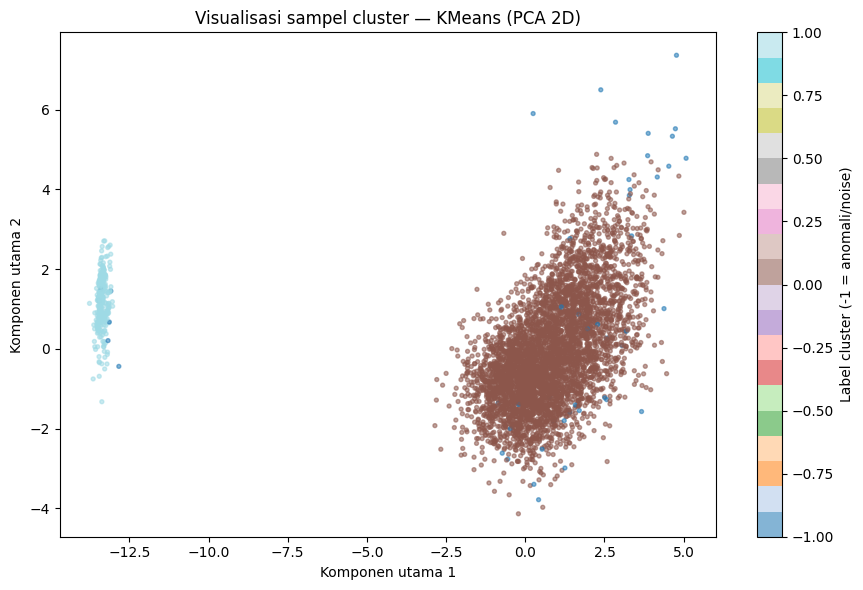

Variansi dijelaskan PCA 2D visualisasi: 32.75%


In [18]:
# Visualisasi hanya mengambil subset agar grafik tetap ringan.
VIS_SAMPLE_SIZE = min(5000, len(X_pca))
vis_idx = rng.choice(len(X_pca), size=VIS_SAMPLE_SIZE, replace=False)
vis_pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_vis = vis_pca.fit_transform(X_scaled[vis_idx])
vis_labels = final_labels[vis_idx]

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_vis[:, 0], X_vis[:, 1], c=vis_labels, s=8, alpha=0.55, cmap='tab20')
plt.title(f'Visualisasi sampel cluster — {FINAL_METHOD} (PCA 2D)')
plt.xlabel('Komponen utama 1')
plt.ylabel('Komponen utama 2')
plt.colorbar(scatter, label='Label cluster (-1 = anomali/noise)')
plt.tight_layout()
plt.show()
print('Variansi dijelaskan PCA 2D visualisasi:', f'{vis_pca.explained_variance_ratio_.sum():.2%}')

## 13. Simpan file hasil sesuai format dosen

File wajib untuk UTS adalah `cluster.csv` dengan tepat dua kolom: `id_pelanggan` dan `cluster`. Satu baris harus tersedia untuk setiap pelanggan. Label cluster berupa integer dan `-1` menandai anomali.

In [19]:
cluster_output = pd.DataFrame({
    'id_pelanggan': df['id_pelanggan'].astype(str),
    'cluster': final_labels.astype(int)
})

assert cluster_output.columns.tolist() == ['id_pelanggan', 'cluster']
assert len(cluster_output) == len(df)
assert cluster_output['id_pelanggan'].is_unique
assert pd.api.types.is_integer_dtype(cluster_output['cluster'])

cluster_output.to_csv('cluster.csv', index=False)
cluster_profile.to_csv('profil_cluster.csv', index=False)

print('File berhasil dibuat: cluster.csv dan profil_cluster.csv')
print('Ukuran cluster:')
display(cluster_output['cluster'].value_counts().sort_index().rename('jumlah_pelanggan').to_frame())
display(cluster_output.head())

File berhasil dibuat: cluster.csv dan profil_cluster.csv
Ukuran cluster:


,jumlah_pelanggan
cluster,
-1,1201
0,112131
1,6668


,id_pelanggan,cluster
0,C864291,0
1,C115620,0
2,C903774,0
3,C716498,0
4,C936513,0


In [20]:
# Download hasil utama dan tabel pendukung dari Google Colab.
from google.colab import files
files.download('cluster.csv')
files.download('profil_cluster.csv')
files.download('feature_sensitivity_summary.csv')
files.download('stability_sensitivity.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Catatan untuk laporan dan ujian lisan

Sebelum menyelesaikan laporan, catat dan jelaskan hasil aktual berikut:

- Alasan `id_pelanggan` tidak digunakan sebagai fitur.
- Bagaimana nilai kosong `rata2_keranjang` ditangani dan bukti bahwa baris tersebut tidak memiliki transaksi.
- Mengapa kolom komposisi diubah menggunakan CLR.
- Mengapa fitur tertentu ditransformasi `log1p`, lalu diskalakan dengan `RobustScaler`.
- Hasil sensitivitas fitur anonim: bandingkan `feature_sensitivity_summary.csv`; jelaskan bahwa n01-n15 diuji dengan signed-log, sedangkan arti n11-n15 tidak dirinci pada kamus data.
- Nilai Silhouette dan Davies–Bouldin untuk pemilihan jumlah cluster.
- BIC untuk GMM, serta jumlah cluster/noise HDBSCAN.
- Hasil stability dari 10 subsampling (70% data latih per subsampel), `n_init=10`, dan rata-rata ARI.
- Profil, nama, dan satu usulan strategi pemasaran untuk setiap cluster, termasuk perlakuan hati-hati pada anomali.
- Metode final, aturan penentuan anomali `-1`, serta persentase pelanggan yang ditandai sebagai anomali.

### Catatan keterbatasan
ARI antara dua hasil feature set adalah ukuran kesepakatan kedua model, bukan ARI terhadap hidden reference dosen. Nilai terhadap hidden reference hanya dapat dihitung oleh sistem penilaian dosen.
